# Deep Learning Project 1 — Modified ResNet on CIFAR-10 (≤ 5M parameters)

**Team:** Akhil Vardhan Mallipeddu(am16362)

This notebook trains a **wide 3-stage ResNet (4,798,810 parameters)** from scratch on CIFAR-10, validates on a
stratified 5,000-image hold-out of the competition training set, and writes a Kaggle `submission.csv` for the unlabeled competition test set.

| Design choice | Value | Why |
|---|---|---|
| Residual layers `N` | 3 | Keeps all compute at 32×32 → 16×16 → 8×8. A 4th stage at 4×4 spends ~70% of the parameter budget on a tiny feature map. |
| Channels `C_i` | 80 / 160 / 320 | Wider beats deeper at a fixed parameter budget on CIFAR (Wide-ResNet finding). |
| Blocks `B_i` | 2 / 3 / 2 | Extra block in the middle stage, where width/resolution balance is best. |
| Conv kernel `F_i` | 3×3 | Standard; larger kernels cost params quadratically for little gain at 32×32. |
| Skip kernel `K_i` | 1×1 (stride 2 when downsampling) | Cheapest projection shortcut. |
| Pool `P` | Global average (8×8) | Equivalent to `P = 8` here. |
| Optimizer | SGD + Nesterov, momentum 0.9, wd 5e-4 (no wd on BN/bias) | Best-generalizing choice for ResNets on CIFAR. |
| Schedule | One-cycle, peak LR 0.1, 200 epochs | Fast convergence, strong final accuracy. |
| Augmentation | Random crop (reflect pad 4) + flip + AutoAugment (CIFAR-10 policy) + Cutout 16 | Main source of accuracy beyond ~93%. |
| Regularization | Label smoothing 0.1, weight EMA (decay 0.999) | Smoother, better-calibrated model; EMA usually adds +0.2–0.5%. |
| Inference | Horizontal-flip TTA | Free ~+0.1–0.3%. |

**Runs on:** local RTX 3070 (8 GB) and Colab A100. Mixed precision (bf16 on Ampere) and `channels_last` are enabled automatically.
Expected: roughly **96%+ validation accuracy** after 200 epochs. The Kaggle test set is a *different* version of CIFAR-10, so Kaggle accuracy is usually lower than validation accuracy.

**How to use:** set paths in the **Config** cell, then *Run All*. Training resumes automatically from `checkpoints/` if interrupted.

**References:** He et al. 2016 (ResNet); Zagoruyko & Komodakis 2016 (Wide ResNets); Cubuk et al. 2019 (AutoAugment);
DeVries & Taylor 2017 (Cutout); Smith & Topin 2019 (one-cycle LR); Szegedy et al. 2016 (label smoothing);
model code structure adapted from [kuangliu/pytorch-cifar](https://github.com/kuangliu/pytorch-cifar).

## 1. Setup

In [1]:
import os, sys, platform, subprocess, time, math, json, random, pickle, glob, copy

IN_COLAB = "google.colab" in sys.modules
IS_WINDOWS = platform.system() == "Windows"

def pip_install(*pkgs):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pkgs])

for mod, pkg in [("torchsummary", "torchsummary"), ("tqdm", "tqdm"), ("pandas", "pandas"), ("matplotlib", "matplotlib")]:
    try:
        __import__(mod)
    except ImportError:
        pip_install(pkg)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Python {platform.python_version()} | PyTorch {torch.__version__} | torchvision {torchvision.__version__}")
print(f"Platform: {platform.system()} | Colab: {IN_COLAB} | Device: {device}")
if device.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    print(f"GPU: {props.name} | {props.total_memory / 1024**3:.1f} GB | compute capability {props.major}.{props.minor}")
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
else:
    print("WARNING: no GPU found - training will be extremely slow.")

Python 3.11.3 | PyTorch 2.14.1+cu126 | torchvision 0.29.1+cu126
Platform: Windows | Colab: False | Device: cuda
GPU: NVIDIA GeForce RTX 3070 Laptop GPU | 8.0 GB | compute capability 8.6


## 2. Config

Everything you might want to change is here. Defaults are tuned for the best accuracy; they are the same on the RTX 3070 and the A100
(only data-loader workers and `torch.compile` differ, which affect speed, not accuracy).

**Approximate time for 200 epochs:** A100 ≈ 35–50 min, RTX 3070 ≈ 1.5–2.5 h (CPU-side augmentation speed matters on local machines).
If you're short on time, `epochs = 120` typically loses only ~0.3%.

**Colab tip:** mount Google Drive and point `ckpt_dir` at it so a disconnect doesn't lose progress
(`from google.colab import drive; drive.mount('/content/drive')`, then `ckpt_dir = '/content/drive/MyDrive/dl_project1/checkpoints'`).

In [2]:
CFG = dict(
    # ---- data ----
    data_root = "./data",          # where the Kaggle files live (train_images/, test_images/, *.csv; searched recursively)
    kaggle_competition = "",       # optional: Kaggle competition slug to auto-download (needs ~/.kaggle/kaggle.json)
    val_size = 5000,               # stratified hold-out from the 50k competition training images for validation
    subset = None,                 # e.g. 2000 for a quick smoke test of the whole pipeline; None = full data

    # ---- model (parameters you can change, per the assignment) ----
    channels = (80, 160, 320),     # C_i
    blocks   = (2, 3, 2),          # B_i  (N = len(blocks) residual layers)
    conv_kernel = 3,               # F_i
    skip_kernel = 1,               # K_i

    # ---- optimization ----
    epochs = 200,
    batch_size = 128,
    lr = 0.1,                      # peak LR of the one-cycle schedule (for batch 128)
    momentum = 0.9,
    weight_decay = 5e-4,
    pct_start = 0.15,              # fraction of training spent warming up
    label_smoothing = 0.1,
    grad_clip = None,              # e.g. 5.0; not needed with this recipe
    ema_decay = 0.999,

    # ---- augmentation ----
    policy = "autoaugment",        # 'autoaugment' | 'trivialaugment' | 'randaugment' | 'none'
    cutout = 16,                   # Cutout patch size (0 disables)
    cutmix_prob = 0.0,             # optional CutMix probability (try 0.5 if you see overfitting)

    # ---- system ----
    seed = 42,
    num_workers = min(8, os.cpu_count() or 2),
    use_compile = (device.type == "cuda") and not IS_WINDOWS,   # torch.compile: needs Triton (Linux); faster on A100
    channels_last = True,
    ckpt_dir = "./checkpoints",
    resume = True,                 # resume from ckpt_dir/<run_name>_last.pt if it exists
    out_dir = "./outputs",
)

gpu_tag = (torch.cuda.get_device_name(0).split()[-1].lower() if device.type == "cuda" else "cpu")
CFG["run_name"] = f"wresnet_{'-'.join(map(str, CFG['channels']))}_{'-'.join(map(str, CFG['blocks']))}_{gpu_tag}"
os.makedirs(CFG["data_root"], exist_ok=True); os.makedirs(CFG["ckpt_dir"], exist_ok=True); os.makedirs(CFG["out_dir"], exist_ok=True)

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(CFG["seed"])

# Mixed precision: bf16 on Ampere+ (RTX 30xx, A100) needs no loss scaling; fp16 + GradScaler otherwise.
USE_AMP = device.type == "cuda"
AMP_DTYPE = torch.bfloat16 if (USE_AMP and torch.cuda.is_bf16_supported()) else torch.float16
print(json.dumps({k: (str(v) if isinstance(v, tuple) else v) for k, v in CFG.items()}, indent=2))
print("AMP dtype:", AMP_DTYPE if USE_AMP else "disabled")

{
  "data_root": "./data",
  "kaggle_competition": "",
  "val_size": 5000,
  "subset": null,
  "channels": "(80, 160, 320)",
  "blocks": "(2, 3, 2)",
  "conv_kernel": 3,
  "skip_kernel": 1,
  "epochs": 200,
  "batch_size": 128,
  "lr": 0.1,
  "momentum": 0.9,
  "weight_decay": 0.0005,
  "pct_start": 0.15,
  "label_smoothing": 0.1,
  "grad_clip": null,
  "ema_decay": 0.999,
  "policy": "autoaugment",
  "cutout": 16,
  "cutmix_prob": 0.0,
  "seed": 42,
  "num_workers": 8,
  "use_compile": false,
  "channels_last": true,
  "ckpt_dir": "./checkpoints",
  "resume": true,
  "out_dir": "./outputs",
  "run_name": "wresnet_80-160-320_2-3-2_gpu"
}
AMP dtype: torch.bfloat16


## 3. Data

Loads the Kaggle competition files from `data_root` (extracting `data.zip` if needed):
`train_labels.csv` + `train_images/*.png` (50,000 labeled) and `test.csv` + `test_images/*.png` (2,000 unlabeled).
- **Train:** 45,000 images (competition training set minus the hold-out)
- **Validation:** stratified 5,000-image hold-out (500 per class) — used for model selection and reported accuracy
- **Kaggle test:** the 2,000 unlabeled images → `submission.csv`

In [3]:
# Optional: download the competition files with the Kaggle API
import zipfile
if CFG["kaggle_competition"]:
    pip_install("kaggle")
    subprocess.check_call(["kaggle", "competitions", "download", "-c", CFG["kaggle_competition"], "-p", CFG["data_root"]])

SEARCH_ROOTS = [CFG["data_root"], "/kaggle/input"]

def find_files(pattern):
    hits = []
    for root in SEARCH_ROOTS:
        if os.path.isdir(root):
            hits += glob.glob(os.path.join(root, "**", pattern), recursive=True)
    return sorted(set(hits))

# Extract data.zip (next to the notebook or inside data_root) if the CSVs aren't there yet
if not find_files("train_labels.csv"):
    for z in glob.glob("*.zip") + glob.glob(os.path.join(CFG["data_root"], "*.zip")):
        print("Extracting", z)
        with zipfile.ZipFile(z) as f:
            f.extractall(CFG["data_root"])

from PIL import Image
from concurrent.futures import ThreadPoolExecutor

def load_pngs(folder, filenames):
    # Returns (N, 32, 32, 3) uint8 in the order of `filenames`.
    def _load(fn):
        with Image.open(os.path.join(folder, fn)) as im:
            return np.asarray(im.convert("RGB"), dtype=np.uint8)
    with ThreadPoolExecutor(16) as ex:
        return np.stack(list(ex.map(_load, filenames)))

CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

labels_csv = find_files("train_labels.csv")
assert labels_csv, f"train_labels.csv not found under {SEARCH_ROOTS} - put the Kaggle files (or data.zip) there."
data_dir = os.path.dirname(labels_csv[0])
train_df = pd.read_csv(labels_csv[0])
test_df = pd.read_csv(os.path.join(data_dir, "test.csv"))

t0 = time.time()
x_all = load_pngs(os.path.join(data_dir, "train_images"), train_df["filename"])
y_all = train_df["label"].to_numpy(dtype=np.int64)
x_test = load_pngs(os.path.join(data_dir, "test_images"), test_df["filename"])
test_ids = test_df["id"].to_numpy()
print(f"Loaded {len(x_all)} train + {len(x_test)} test PNGs from {data_dir} in {time.time() - t0:.0f}s")

# Stratified train / validation split
rng = np.random.RandomState(CFG["seed"])
val_idx = np.concatenate([rng.permutation(np.where(y_all == c)[0])[:CFG["val_size"] // 10] for c in range(10)])
train_mask = np.ones(len(y_all), dtype=bool); train_mask[val_idx] = False
x_train, y_train = x_all[train_mask], y_all[train_mask]
x_val, y_val = x_all[val_idx], y_all[val_idx]

if CFG["subset"]:
    x_train, y_train = x_train[:CFG["subset"]], y_train[:CFG["subset"]]
    x_val, y_val = x_val[:CFG["subset"] // 5], y_val[:CFG["subset"] // 5]
print(f"train {x_train.shape}, val {x_val.shape}, test {x_test.shape}")
print("train class counts:", np.bincount(y_train, minlength=10).tolist())
print("classes:", CLASSES)

Loaded 50000 train + 2000 test PNGs from ./data in 34s
train (45000, 32, 32, 3), val (5000, 32, 32, 3), test (2000, 32, 32, 3)
train class counts: [4500, 4500, 4500, 4500, 4500, 4500, 4500, 4500, 4500, 4500]
classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


### Data pipeline
The dataset/transform code is written to `cifar_data.py` so DataLoader worker processes can import it — this is what makes
multi-worker loading work in Jupyter on **Windows** (local RTX 3070) as well as Linux/Colab.

In [4]:
CIFAR_DATA_SRC = """
import numpy as np
import torch
from PIL import Image
from torch.utils.data import Dataset
import torchvision.transforms as T

CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)


class Cutout:
    # Zero out one random size x size square (DeVries & Taylor, 2017). Operates on a normalized CHW tensor.
    def __init__(self, size=16):
        self.size = size

    def __call__(self, img):
        _, h, w = img.shape
        cy, cx = torch.randint(h, (1,)).item(), torch.randint(w, (1,)).item()
        y0, y1 = max(0, cy - self.size // 2), min(h, cy + self.size // 2)
        x0, x1 = max(0, cx - self.size // 2), min(w, cx + self.size // 2)
        img = img.clone()
        img[:, y0:y1, x0:x1] = 0.0
        return img


def build_transform(train, policy="autoaugment", cutout=16):
    if not train:
        return T.Compose([T.ToTensor(), T.Normalize(CIFAR_MEAN, CIFAR_STD)])
    t = [T.RandomCrop(32, padding=4, padding_mode="reflect"), T.RandomHorizontalFlip()]
    if policy == "autoaugment":
        t.append(T.AutoAugment(T.AutoAugmentPolicy.CIFAR10))
    elif policy == "trivialaugment":
        t.append(T.TrivialAugmentWide())
    elif policy == "randaugment":
        t.append(T.RandAugment(num_ops=2, magnitude=9))
    t += [T.ToTensor(), T.Normalize(CIFAR_MEAN, CIFAR_STD)]
    if cutout:
        t.append(Cutout(cutout))
    return T.Compose(t)


class ArrayDataset(Dataset):
    # images: (N, 32, 32, 3) uint8; labels: (N,) int or None (returns index instead of label).
    def __init__(self, images, labels=None, transform=None):
        self.images, self.labels, self.transform = images, labels, transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        img = Image.fromarray(self.images[i])
        if self.transform is not None:
            img = self.transform(img)
        return img, (int(self.labels[i]) if self.labels is not None else i)
"""
with open("cifar_data.py", "w") as f:
    f.write(CIFAR_DATA_SRC)

import importlib, cifar_data
importlib.reload(cifar_data)
from cifar_data import ArrayDataset, build_transform, CIFAR_MEAN, CIFAR_STD

train_ds = ArrayDataset(x_train, y_train, build_transform(True, CFG["policy"], CFG["cutout"]))
val_ds = ArrayDataset(x_val, y_val, build_transform(False))
train_eval_ds = ArrayDataset(x_train, y_train, build_transform(False))   # clean (un-augmented) training accuracy

nw = CFG["num_workers"]
loader_kw = dict(num_workers=nw, pin_memory=(device.type == "cuda"), persistent_workers=nw > 0)
if nw > 0:
    loader_kw["prefetch_factor"] = 4
train_loader = DataLoader(train_ds, batch_size=CFG["batch_size"], shuffle=True, drop_last=True, **loader_kw)
val_loader = DataLoader(val_ds, batch_size=512, shuffle=False, **loader_kw)
train_eval_loader = DataLoader(train_eval_ds, batch_size=512, shuffle=False, num_workers=nw, pin_memory=loader_kw["pin_memory"])
print(f"{len(train_loader)} train steps/epoch, {nw} workers")

351 train steps/epoch, 8 workers


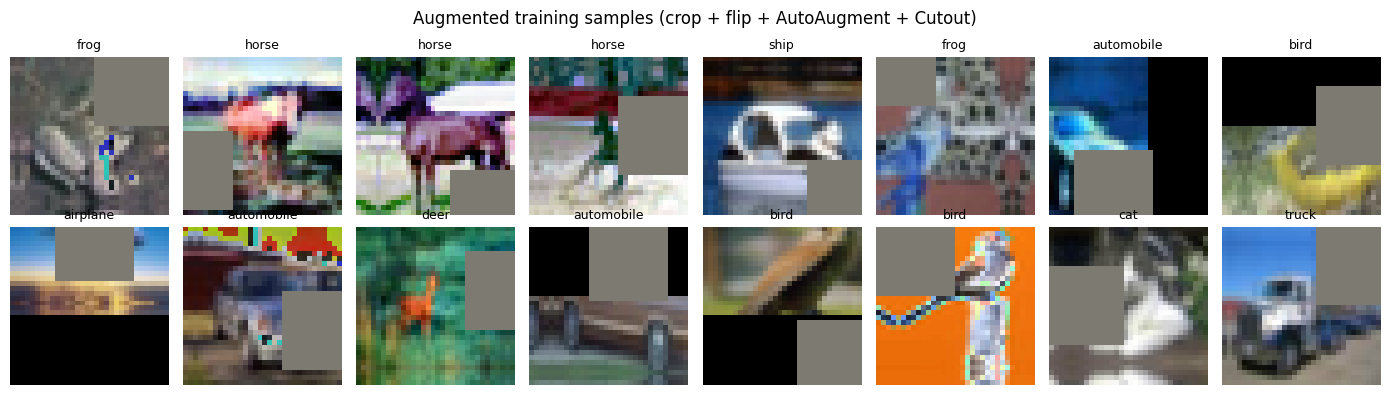

In [5]:
# Peek at augmented training images
def denorm(t):
    m = torch.tensor(CIFAR_MEAN).view(3, 1, 1); s = torch.tensor(CIFAR_STD).view(3, 1, 1)
    return (t * s + m).clamp(0, 1).permute(1, 2, 0).numpy()

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, i in zip(axes.flat, np.random.choice(len(train_ds), 16, replace=False)):
    img, lbl = train_ds[i]
    ax.imshow(denorm(img)); ax.set_title(CLASSES[lbl], fontsize=9); ax.axis("off")
plt.suptitle("Augmented training samples (crop + flip + AutoAugment + Cutout)"); plt.tight_layout(); plt.show()

## 4. Model

`ReLU(S(x) + F(x))` residual blocks, with `F = conv → BN → ReLU → conv → BN` and `S` = identity or a 1×1 strided projection.
The last BN in each block starts at zero (each block begins as an identity map), which makes deep residual nets train more smoothly.

In [6]:
class BasicBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1, conv_kernel=3, skip_kernel=1):
        super().__init__()
        p = conv_kernel // 2
        self.conv1 = nn.Conv2d(in_ch, out_ch, conv_kernel, stride, p, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, conv_kernel, 1, p, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.shortcut = nn.Identity()
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, skip_kernel, stride, skip_kernel // 2, bias=False),
                nn.BatchNorm2d(out_ch))

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x), inplace=True)


class ResNetCIFAR(nn.Module):
    def __init__(self, channels=(80, 160, 320), blocks=(2, 3, 2), conv_kernel=3, skip_kernel=1, num_classes=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, channels[0], 3, 1, 1, bias=False),
                                  nn.BatchNorm2d(channels[0]), nn.ReLU(inplace=True))
        layers, in_ch = [], channels[0]
        for i, (ch, n) in enumerate(zip(channels, blocks)):
            for j in range(n):
                stride = 2 if (i > 0 and j == 0) else 1
                layers.append(BasicBlock(in_ch, ch, stride, conv_kernel, skip_kernel))
                in_ch = ch
        self.layers = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(1)         # global average pool (P = final feature-map size, 8x8)
        self.fc = nn.Linear(in_ch, num_classes)
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
        for m in self.modules():
            if isinstance(m, BasicBlock):
                nn.init.zeros_(m.bn2.weight)        # zero-init residual branch

    def forward(self, x):
        x = self.layers(self.stem(x))
        return self.fc(torch.flatten(self.pool(x), 1))


model = ResNetCIFAR(CFG["channels"], CFG["blocks"], CFG["conv_kernel"], CFG["skip_kernel"]).to(device)
N_PARAMS = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {N_PARAMS:,}")
assert N_PARAMS <= 5_000_000, "Model exceeds the 5M parameter limit!"

try:
    from torchsummary import summary
    summary(model, (3, 32, 32), device=device.type)
except Exception as e:
    print("torchsummary failed:", e)

if CFG["channels_last"] and device.type == "cuda":
    model = model.to(memory_format=torch.channels_last)

Trainable parameters: 4,798,810
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 80, 32, 32]           2,160
       BatchNorm2d-2           [-1, 80, 32, 32]             160
              ReLU-3           [-1, 80, 32, 32]               0
            Conv2d-4           [-1, 80, 32, 32]          57,600
       BatchNorm2d-5           [-1, 80, 32, 32]             160
            Conv2d-6           [-1, 80, 32, 32]          57,600
       BatchNorm2d-7           [-1, 80, 32, 32]             160
          Identity-8           [-1, 80, 32, 32]               0
        BasicBlock-9           [-1, 80, 32, 32]               0
           Conv2d-10           [-1, 80, 32, 32]          57,600
      BatchNorm2d-11           [-1, 80, 32, 32]             160
           Conv2d-12           [-1, 80, 32, 32]          57,600
      BatchNorm2d-13           [-1, 80, 32, 32]             160
       

## 5. Training utilities

In [7]:
class EMA:
    # Exponential moving average of weights (BN running stats are copied/averaged too).
    def __init__(self, model, decay):
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)
        self.decay = decay

    @torch.no_grad()
    def update(self, model, step):
        d = min(self.decay, (1 + step) / (10 + step))   # warm-up: average fast early on
        msd = model.state_dict()
        for k, v in self.module.state_dict().items():
            if v.dtype.is_floating_point:
                v.mul_(d).add_(msd[k].detach(), alpha=1 - d)
            else:
                v.copy_(msd[k])


def to_device(x):
    x = x.to(device, non_blocking=True)
    return x.to(memory_format=torch.channels_last) if (CFG["channels_last"] and device.type == "cuda") else x


def autocast():
    return torch.autocast(device_type=device.type, dtype=AMP_DTYPE, enabled=USE_AMP)


@torch.no_grad()
def predict_probs(net, loader, tta=False):
    # Softmax probabilities for every sample in the loader (optionally averaged with horizontal flip).
    net.eval()
    probs, targets = [], []
    for x, y in loader:
        x = to_device(x)
        with autocast():
            p = net(x).float().softmax(1)
            if tta:
                p = (p + net(torch.flip(x, dims=[3])).float().softmax(1)) / 2
        probs.append(p.cpu()); targets.append(y)
    return torch.cat(probs), torch.cat(targets)


@torch.no_grad()
def evaluate(net, loader, tta=False):
    probs, y = predict_probs(net, loader, tta)
    loss = F.nll_loss(torch.log(probs.clamp_min(1e-8)), y).item()
    return loss, (probs.argmax(1) == y).float().mean().item() * 100


def cutmix(x, y, alpha=1.0):
    lam = np.random.beta(alpha, alpha)
    idx = torch.randperm(x.size(0), device=x.device)
    H, W = x.shape[2:]
    rh, rw = int(H * math.sqrt(1 - lam)), int(W * math.sqrt(1 - lam))
    cy, cx = np.random.randint(H), np.random.randint(W)
    y0, y1, x0, x1 = max(cy - rh // 2, 0), min(cy + rh // 2, H), max(cx - rw // 2, 0), min(cx + rw // 2, W)
    x = x.clone(); x[:, :, y0:y1, x0:x1] = x[idx, :, y0:y1, x0:x1]
    lam = 1 - (y1 - y0) * (x1 - x0) / (H * W)
    return x, y, y[idx], lam


# Optimizer: SGD + Nesterov; no weight decay on BatchNorm parameters and biases.
decay, no_decay = [], []
for _, p in model.named_parameters():
    (no_decay if p.ndim <= 1 else decay).append(p)
optimizer = torch.optim.SGD([{"params": decay, "weight_decay": CFG["weight_decay"]},
                             {"params": no_decay, "weight_decay": 0.0}],
                            lr=CFG["lr"], momentum=CFG["momentum"], nesterov=True)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=CFG["lr"], epochs=CFG["epochs"], steps_per_epoch=len(train_loader),
    pct_start=CFG["pct_start"], anneal_strategy="cos", div_factor=25.0, final_div_factor=1e4)
criterion = nn.CrossEntropyLoss(label_smoothing=CFG["label_smoothing"])
use_scaler = USE_AMP and AMP_DTYPE == torch.float16
try:
    scaler = torch.amp.GradScaler("cuda", enabled=use_scaler)
except (AttributeError, TypeError):
    scaler = torch.cuda.amp.GradScaler(enabled=use_scaler)
ema = EMA(model, CFG["ema_decay"])

train_model = model
if CFG["use_compile"]:
    try:
        train_model = torch.compile(model)
        print("torch.compile enabled (first epoch includes compile time)")
    except Exception as e:
        print("torch.compile unavailable, continuing without it:", e)

LAST_CKPT = os.path.join(CFG["ckpt_dir"], f"{CFG['run_name']}_last.pt")
BEST_CKPT = os.path.join(CFG["ckpt_dir"], f"{CFG['run_name']}_best.pt")
history = []
start_epoch, global_step, best_acc = 0, 0, 0.0

if CFG["resume"] and os.path.exists(LAST_CKPT):
    ck = torch.load(LAST_CKPT, map_location=device, weights_only=False)
    model.load_state_dict(ck["model"]); ema.module.load_state_dict(ck["ema"])
    optimizer.load_state_dict(ck["optimizer"]); scheduler.load_state_dict(ck["scheduler"]); scaler.load_state_dict(ck["scaler"])
    start_epoch, global_step, best_acc, history = ck["epoch"] + 1, ck["global_step"], ck["best_acc"], ck["history"]
    print(f"Resumed from {LAST_CKPT} at epoch {start_epoch} (best val acc so far {best_acc:.2f}%)")
else:
    print("Starting fresh run:", CFG["run_name"])

Starting fresh run: wresnet_80-160-320_2-3-2_gpu


## 6. Train
Each epoch reports training loss/accuracy (on augmented data), validation accuracy for the raw weights, and for the EMA weights.
The best checkpoint (raw or EMA, whichever scores higher on validation) is saved to `checkpoints/`.

In [8]:
for epoch in range(start_epoch, CFG["epochs"]):
    train_model.train()
    t0 = time.time()
    loss_sum = torch.zeros((), device=device); correct = torch.zeros((), device=device); seen = 0
    pbar = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{CFG['epochs']}", leave=False)
    for x, y in pbar:
        x, y = to_device(x), y.to(device, non_blocking=True)
        use_cm = CFG["cutmix_prob"] > 0 and np.random.rand() < CFG["cutmix_prob"]
        if use_cm:
            x, ya, yb, lam = cutmix(x, y)
        with autocast():
            out = train_model(x)
            loss = lam * criterion(out, ya) + (1 - lam) * criterion(out, yb) if use_cm else criterion(out, y)
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        if CFG["grad_clip"]:
            scaler.unscale_(optimizer); nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
        scaler.step(optimizer); scaler.update(); scheduler.step()
        ema.update(model, global_step); global_step += 1
        loss_sum += loss.detach().float() * x.size(0); correct += (out.argmax(1) == y).sum(); seen += x.size(0)

    train_loss, train_acc = loss_sum.item() / seen, correct.item() / seen * 100
    val_loss, val_acc = evaluate(model, val_loader)
    ema_loss, ema_acc = evaluate(ema.module, val_loader)
    epoch_time = time.time() - t0
    history.append(dict(epoch=epoch + 1, lr=optimizer.param_groups[0]["lr"], train_loss=train_loss, train_acc=train_acc,
                        val_loss=val_loss, val_acc=val_acc, ema_val_loss=ema_loss, ema_val_acc=ema_acc, time=epoch_time))

    if max(val_acc, ema_acc) > best_acc:
        best_acc = max(val_acc, ema_acc)
        use_ema = ema_acc >= val_acc
        torch.save({"model": (ema.module if use_ema else model).state_dict(), "is_ema": use_ema, "epoch": epoch + 1,
                    "val_acc": best_acc, "cfg": CFG}, BEST_CKPT)
    torch.save({"model": model.state_dict(), "ema": ema.module.state_dict(), "optimizer": optimizer.state_dict(),
                "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(), "epoch": epoch, "global_step": global_step,
                "best_acc": best_acc, "history": history, "cfg": CFG}, LAST_CKPT)

    print(f"Ep {epoch + 1:3d}/{CFG['epochs']} | lr {history[-1]['lr']:.4f} | train loss {train_loss:.3f} acc {train_acc:5.2f}% | "
          f"val loss {val_loss:.3f} acc {val_acc:5.2f}% | EMA val {ema_acc:5.2f}% | best {best_acc:5.2f}% | {epoch_time:.0f}s")

pd.DataFrame(history).to_csv(os.path.join(CFG["out_dir"], f"{CFG['run_name']}_history.csv"), index=False)
print(f"Training done. Best validation accuracy: {best_acc:.2f}%")

Epoch 1/200:   0%|          | 0/351 [00:59<?, ?it/s]

Ep   1/200 | lr 0.0043 | train loss 2.157 acc 21.38% | val loss 1.862 acc 32.30% | EMA val 33.70% | best 33.70% | 189s


Epoch 2/200:   0%|          | 0/351 [00:00<?, ?it/s]

Ep   2/200 | lr 0.0050 | train loss 2.057 acc 26.22% | val loss 1.775 acc 33.78% | EMA val 35.68% | best 35.68% | 34s


Epoch 3/200:   0%|          | 0/351 [00:00<?, ?it/s]

Ep   3/200 | lr 0.0063 | train loss 1.994 acc 29.90% | val loss 1.657 acc 40.26% | EMA val 40.40% | best 40.40% | 33s


... (390 outputs left out)

Epoch 199/200:   0%|          | 0/351 [00:00<?, ?it/s]

Ep 199/200 | lr 0.0000 | train loss 0.632 acc 94.66% | val loss 0.184 acc 96.42% | EMA val 96.44% | best 96.52% | 21s


Epoch 200/200:   0%|          | 0/351 [00:00<?, ?it/s]

Ep 200/200 | lr 0.0000 | train loss 0.631 acc 94.65% | val loss 0.187 acc 96.46% | EMA val 96.44% | best 96.52% | 20s
Training done. Best validation accuracy: 96.52%


## 7. Learning curves

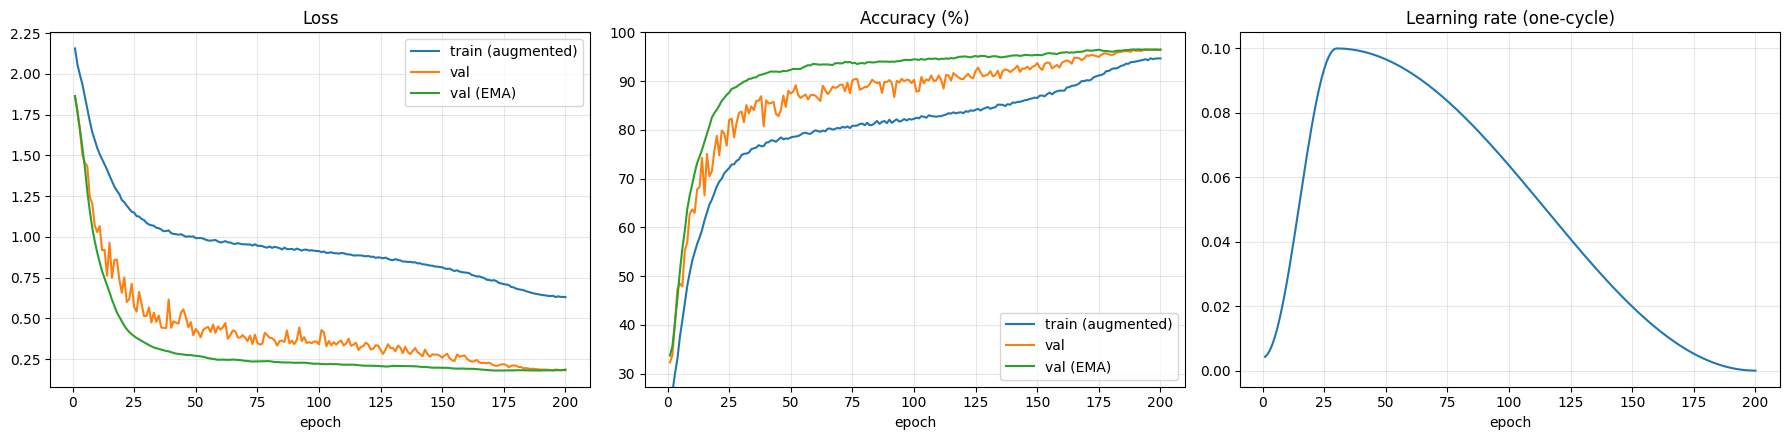

In [9]:
h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].plot(h.epoch, h.train_loss, label="train (augmented)"); ax[0].plot(h.epoch, h.val_loss, label="val"); ax[0].plot(h.epoch, h.ema_val_loss, label="val (EMA)")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(h.epoch, h.train_acc, label="train (augmented)"); ax[1].plot(h.epoch, h.val_acc, label="val"); ax[1].plot(h.epoch, h.ema_val_acc, label="val (EMA)")
ax[1].set_title("Accuracy (%)"); ax[1].set_xlabel("epoch"); ax[1].set_ylim(max(0, h.val_acc.min() - 5), 100); ax[1].legend(); ax[1].grid(alpha=.3)
ax[2].plot(h.epoch, h.lr); ax[2].set_title("Learning rate (one-cycle)"); ax[2].set_xlabel("epoch"); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(CFG["out_dir"], f"{CFG['run_name']}_curves.png"), dpi=150); plt.show()

## 8. Final evaluation (best checkpoint)

In [10]:
ck = torch.load(BEST_CKPT, map_location=device, weights_only=False)
final_model = ResNetCIFAR(CFG["channels"], CFG["blocks"], CFG["conv_kernel"], CFG["skip_kernel"]).to(device)
final_model.load_state_dict(ck["model"])
if CFG["channels_last"] and device.type == "cuda":
    final_model = final_model.to(memory_format=torch.channels_last)
print(f"Loaded best checkpoint from epoch {ck['epoch']} ({'EMA' if ck['is_ema'] else 'raw'} weights)")

_, val_acc_plain = evaluate(final_model, val_loader, tta=False)
val_probs, val_targets = predict_probs(final_model, val_loader, tta=True)
val_preds = val_probs.argmax(1)
val_acc_tta = (val_preds == val_targets).float().mean().item() * 100
_, train_acc_clean = evaluate(final_model, train_eval_loader, tta=False)

final_params = sum(p.numel() for p in final_model.parameters() if p.requires_grad)
print("=" * 60)
print(f"Number of trainable parameters : {final_params:,}  (limit 5,000,000)")
print(f"Training accuracy (clean)      : {train_acc_clean:.2f}%")
print(f"Validation accuracy            : {val_acc_plain:.2f}%")
print(f"Validation accuracy (flip TTA) : {val_acc_tta:.2f}%")
print("=" * 60)

Loaded best checkpoint from epoch 191 (EMA weights)
Number of trainable parameters : 4,798,810  (limit 5,000,000)
Training accuracy (clean)      : 99.92%
Validation accuracy            : 96.52%
Validation accuracy (flip TTA) : 96.64%


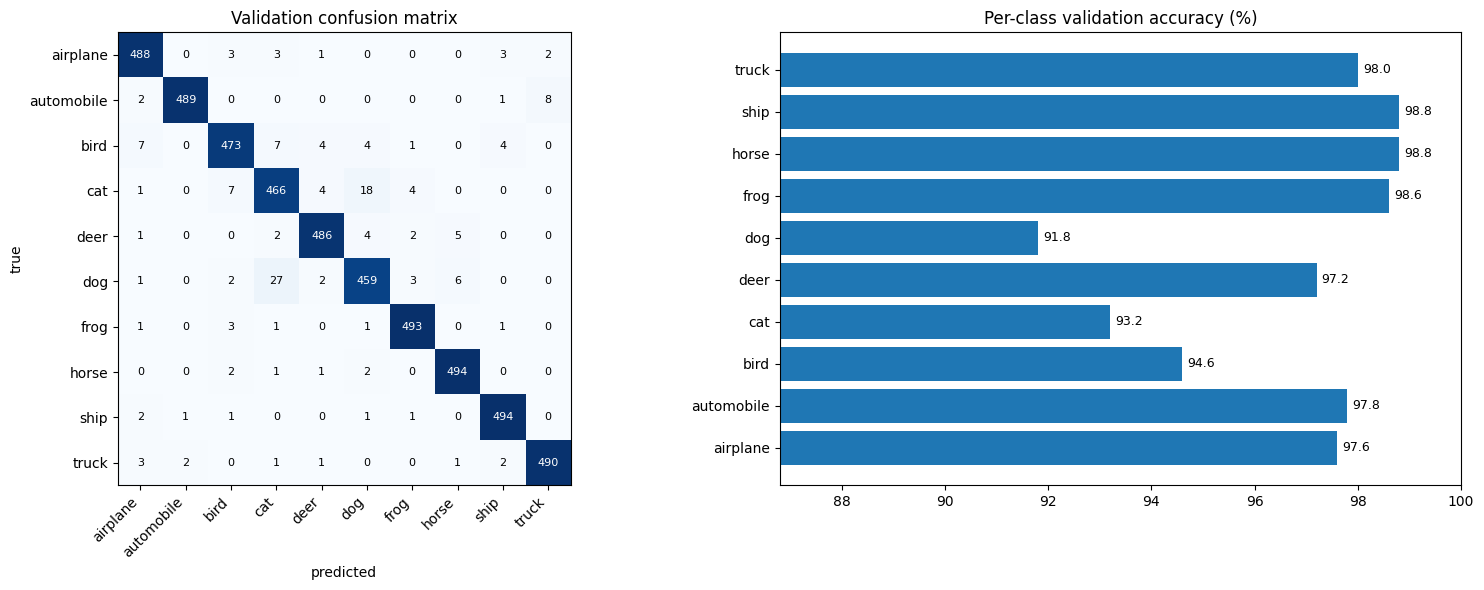

In [11]:
# Confusion matrix and per-class accuracy on the validation set
cm = np.zeros((10, 10), dtype=np.int64)
for t, p in zip(val_targets.numpy(), val_preds.numpy()):
    cm[t, p] += 1
per_class = cm.diagonal() / cm.sum(1) * 100

fig, ax = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.2, 1]})
im = ax[0].imshow(cm, cmap="Blues")
ax[0].set_xticks(range(10)); ax[0].set_xticklabels(CLASSES, rotation=45, ha="right")
ax[0].set_yticks(range(10)); ax[0].set_yticklabels(CLASSES)
for i in range(10):
    for j in range(10):
        ax[0].text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if cm[i, j] > cm.max() / 2 else "black")
ax[0].set_xlabel("predicted"); ax[0].set_ylabel("true"); ax[0].set_title("Validation confusion matrix")
ax[1].barh(CLASSES, per_class); ax[1].set_xlim(per_class.min() - 5, 100); ax[1].set_title("Per-class validation accuracy (%)")
for i, v in enumerate(per_class):
    ax[1].text(v + 0.1, i, f"{v:.1f}", va="center", fontsize=9)
plt.tight_layout(); plt.savefig(os.path.join(CFG["out_dir"], f"{CFG['run_name']}_confusion.png"), dpi=150); plt.show()

## 9. Kaggle submission
Predicts the unlabeled competition test set with flip TTA and writes `outputs/submission.csv`.
Column names are taken from `sample_submission.csv` (`id,label`).

Using columns from ./data\sample_submission.csv: ['id', 'label']
Wrote ./outputs\submission.csv (2000 rows)


,id,label
0,0,6
1,1,3
2,2,3
3,3,9
4,4,3


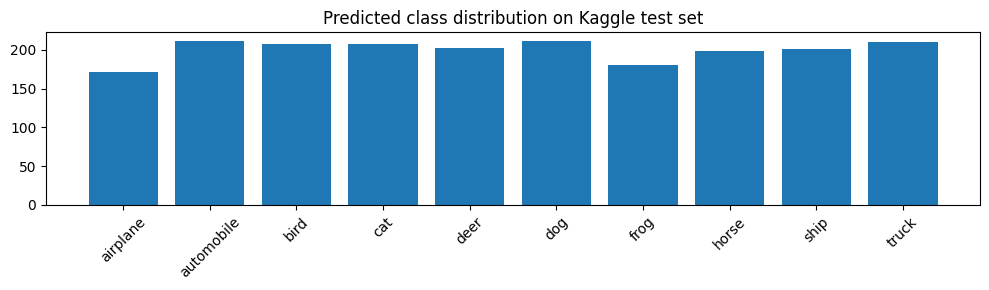

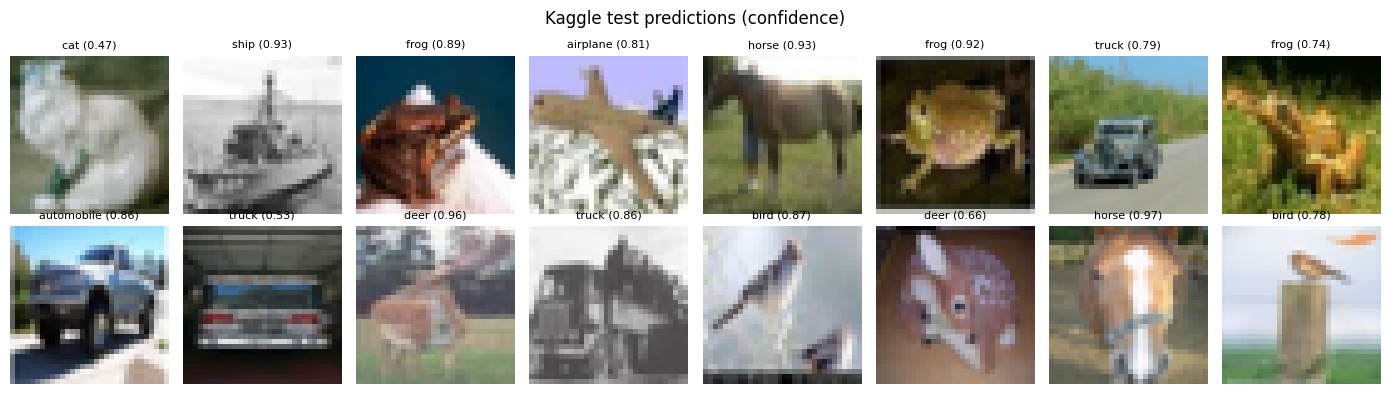

In [12]:
if x_test is not None:
    test_loader = DataLoader(ArrayDataset(x_test, None, build_transform(False)), batch_size=512, shuffle=False,
                             num_workers=nw, pin_memory=(device.type == "cuda"))
    test_probs, _ = predict_probs(final_model, test_loader, tta=True)
    test_preds = test_probs.argmax(1).numpy()

    id_col, label_col = "id", "label"
    samples = find_files("sample_submission*.csv")
    if samples:
        cols = pd.read_csv(samples[0], nrows=1).columns.tolist()
        if len(cols) == 2:
            id_col, label_col = cols
            print(f"Using columns from {samples[0]}: {cols}")

    sub = pd.DataFrame({id_col: test_ids, label_col: test_preds})
    sub_path = os.path.join(CFG["out_dir"], "submission.csv")
    sub.to_csv(sub_path, index=False)
    np.save(os.path.join(CFG["out_dir"], f"{CFG['run_name']}_test_probs.npy"), test_probs.numpy())
    print(f"Wrote {sub_path} ({len(sub)} rows)")
    display(sub.head())

    # Sanity check: predicted class distribution should be roughly balanced
    counts = np.bincount(test_preds, minlength=10)
    plt.figure(figsize=(10, 3)); plt.bar(CLASSES, counts); plt.xticks(rotation=45)
    plt.title("Predicted class distribution on Kaggle test set"); plt.tight_layout(); plt.show()

    # A few test images with predictions
    fig, axes = plt.subplots(2, 8, figsize=(14, 4))
    for ax, i in zip(axes.flat, np.random.choice(len(x_test), 16, replace=False)):
        ax.imshow(x_test[i]); ax.set_title(f"{CLASSES[test_preds[i]]} ({test_probs[i].max():.2f})", fontsize=8); ax.axis("off")
    plt.suptitle("Kaggle test predictions (confidence)"); plt.tight_layout(); plt.show()
else:
    print("No Kaggle test file loaded - skipping submission.")

## 10. Summary

In [13]:
summary_dict = {
    "run_name": CFG["run_name"],
    "architecture": f"ResNet, N={len(CFG['blocks'])} layers, C={CFG['channels']}, B={CFG['blocks']}, "
                    f"F={CFG['conv_kernel']}, K={CFG['skip_kernel']}, global avg pool",
    "trainable_params": final_params,
    "epochs": CFG["epochs"],
    "best_epoch": ck["epoch"],
    "weights": "EMA" if ck["is_ema"] else "raw",
    "train_acc_clean": round(train_acc_clean, 2),
    "val_acc": round(val_acc_plain, 2),
    "val_acc_tta": round(val_acc_tta, 2),
    "gpu": torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu",
    "total_train_time_min": round(sum(r["time"] for r in history) / 60, 1),
}
with open(os.path.join(CFG["out_dir"], f"{CFG['run_name']}_summary.json"), "w") as f:
    json.dump(summary_dict, f, indent=2)
for k, v in summary_dict.items():
    print(f"{k:>22}: {v}")
print(f"\nFINAL VALIDATION ACCURACY: {val_acc_tta:.2f}%  |  PARAMETERS: {final_params:,}")

              run_name: wresnet_80-160-320_2-3-2_gpu
          architecture: ResNet, N=3 layers, C=(80, 160, 320), B=(2, 3, 2), F=3, K=1, global avg pool
      trainable_params: 4798810
                epochs: 200
            best_epoch: 191
               weights: EMA
       train_acc_clean: 99.92
               val_acc: 96.52
           val_acc_tta: 96.64
                   gpu: NVIDIA GeForce RTX 3070 Laptop GPU
  total_train_time_min: 76.8

FINAL VALIDATION ACCURACY: 96.64%  |  PARAMETERS: 4,798,810
